# Customer Lifecycle & Repeat Purchase | Python

**Business question:** Which customers bought once, which returned, and which historical groups are worth investigating for retention?

We go from invoice lines to purchase invoices, then to one row per customer. From there we measure repeat purchase and summarise customer groups using recency, frequency and recorded value.

Source: [Online Retail II](https://doi.org/10.24432/C5CG6D), a historical UK retailer dataset. The bundled CSV is read directly from its gzip file. Amounts are in GBP.

## 1. Load and inspect the invoice lines

One source row is an **invoice line**. An invoice can contain several product or charge lines. `Invoice` and `StockCode` are identifiers, so we read them as text. We use the end of the full source as the observation end, even though some of its rows will be excluded from customer analysis.

In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA = Path("data/online_retail_II.csv.gz")
OUTPUT = Path("outputs")
ACTIVE_DAYS = 90
DORMANT_AFTER_DAYS = 180
REPEAT_WINDOW_DAYS = 90
CREDIT_REVIEW_SHARE = 0.50

raw = pd.read_csv(DATA, dtype={"Invoice": "string", "StockCode": "string"})
source_dates = pd.to_datetime(raw["InvoiceDate"], format="%Y-%m-%d %H:%M:%S", errors="coerce")
observation_end = source_dates.max()
snapshot_date = observation_end.normalize() + pd.Timedelta(days=1)

print(f"Invoice lines: {len(raw):,}")
print(f"Source coverage: {source_dates.min()} to {observation_end}")
print(f"Missing customer IDs: {raw['Customer ID'].isna().sum():,}")
display(raw.head(3))

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom


## 2. Clean, then separate purchases and credits

Customer analysis needs a usable customer ID, date, invoice code and stock code. Keep positive quantities on purchase invoices and negative quantities on cancellation invoices (`C` prefix), with a positive unit price in both cases. Remove exact duplicate rows after these checks. The source has no line ID, so treating identical rows as duplicate records is an assumption. Credits reduce recorded value but do not count as new purchases.

In [2]:
identified = raw.dropna(subset=["Customer ID"]).copy()
identified["Invoice"] = identified["Invoice"].str.strip()
identified["StockCode"] = identified["StockCode"].str.strip()
identified["InvoiceDate"] = source_dates.loc[identified.index]

cancelled = identified["Invoice"].str.upper().str.startswith("C", na=False)
valid_purchase = ~cancelled & identified["Quantity"].gt(0)
valid_credit = cancelled & identified["Quantity"].lt(0)

valid = identified.dropna(subset=["Invoice", "StockCode", "InvoiceDate", "Quantity", "Price"])
valid = valid.loc[
    valid["Invoice"].ne("") & valid["StockCode"].ne("")
    & valid["Customer ID"].gt(0) & valid["Customer ID"].mod(1).eq(0)
    & valid["Quantity"].mod(1).eq(0) & valid["Price"].gt(0)
    & (valid_purchase | valid_credit).loc[valid.index]
]
clean = valid.drop_duplicates().copy()
clean["Customer ID"] = clean["Customer ID"].astype("int64")
clean["LineValueGBP"] = clean["Quantity"] * clean["Price"]
purchases = clean.loc[clean["Quantity"].gt(0)]
credits = clean.loc[clean["Quantity"].lt(0)]

cleaning = pd.Series({
    "Source lines": len(raw),
    "With customer ID": len(identified),
    "With valid purchase or credit fields": len(valid),
    "After exact deduplication": len(clean),
    "Purchase lines": len(purchases),
    "Credit lines": len(credits),
}, name="Rows")
assert len(clean) == len(purchases) + len(credits)
display(cleaning.to_frame())

,Rows
Source lines,1067371
With customer ID,824364
With valid purchase or credit fields,824293
After exact deduplication,797815
Purchase lines,779425
Credit lines,18390


## 3. Build purchase invoices and customer RFM metrics

Group lines by customer and invoice to get one purchase invoice per row. The earliest line time gives the invoice time. Then group invoices by customer. **R** is days since the last observed purchase, **F** is the number of distinct purchase invoices, and **M** is gross purchase value minus recorded credits. Credit-only IDs have no purchase history and are outside the customer table.

In [3]:
orders = purchases.groupby(["Customer ID", "Invoice"], as_index=False).agg(
    OrderDate=("InvoiceDate", "min"),
    OrderGrossValueGBP=("LineValueGBP", "sum"),
)
orders = orders.sort_values(["Customer ID", "OrderDate", "Invoice"])
orders["OrderNumber"] = orders.groupby("Customer ID").cumcount() + 1

customers = orders.groupby("Customer ID", as_index=False).agg(
    FirstObservedPurchase=("OrderDate", "min"),
    LastObservedPurchase=("OrderDate", "max"),
    Orders=("Invoice", "size"),
    GrossPurchaseValueGBP=("OrderGrossValueGBP", "sum"),
)
credit_values = -credits.groupby("Customer ID")["LineValueGBP"].sum()
customers["CreditValueGBP"] = customers["Customer ID"].map(credit_values).fillna(0)
customers["NetRecordedValueGBP"] = customers["GrossPurchaseValueGBP"] - customers["CreditValueGBP"]
customers["RecencyDays"] = (snapshot_date - customers["LastObservedPurchase"].dt.normalize()).dt.days

assert customers["Customer ID"].is_unique
assert customers["Orders"].sum() == len(orders)
assert abs(orders["OrderGrossValueGBP"].sum() - purchases["LineValueGBP"].sum()) < 0.01
display(customers.head(3))

,Customer ID,FirstObservedPurchase,LastObservedPurchase,Orders,GrossPurchaseValueGBP,CreditValueGBP,NetRecordedValueGBP,RecencyDays
0,12346,2009-12-14 08:34:00,2011-01-18 10:01:00,12,77556.46,77608.2,-51.74,326
1,12347,2010-10-31 14:20:00,2011-12-07 15:52:00,8,4921.53,0.0,4921.53,3
2,12348,2010-09-27 14:59:00,2011-09-25 13:13:00,5,2019.40,0.0,2019.40,76


## 4. Measure repeat purchase on a fair window

Overall repeat counts anyone with at least two purchase invoices, even though customers have different follow-up times. For **90-day repeat**, only include customers whose first observed purchase is at least 90 full days before the source ends. Of those eligible customers, count the ones whose second invoice arrived within 90 elapsed days. A second invoice on the same day counts and may represent the same visit.

In [4]:
second_orders = orders.loc[orders["OrderNumber"].eq(2), ["Customer ID", "OrderDate"]]
second_orders = second_orders.rename(columns={"OrderDate": "SecondObservedPurchase"})
customers = customers.merge(second_orders, on="Customer ID", how="left", validate="one_to_one")

repeat_window = pd.Timedelta(days=REPEAT_WINDOW_DAYS)
time_to_second = customers["SecondObservedPurchase"] - customers["FirstObservedPurchase"]
customers["RepeatCustomer"] = customers["Orders"].ge(2)
customers["Eligible90"] = customers["FirstObservedPurchase"] + repeat_window <= observation_end
customers["SecondOrderWithin90"] = customers["Eligible90"] & time_to_second.le(repeat_window)

eligible = customers.loc[customers["Eligible90"]]
repeat_90 = int(eligible["SecondOrderWithin90"].sum())
repeat_history = int(customers["RepeatCustomer"].sum())
assert len(eligible) > 0, "The 90-day repeat rate requires customers with full follow-up."
assert repeat_90 <= repeat_history <= len(customers)

print(f"All-history repeat: {repeat_history:,} / {len(customers):,} = {repeat_history / len(customers):.1%}")
print(f"90-day repeat: {repeat_90:,} / {len(eligible):,} = {repeat_90 / len(eligible):.1%}")

## 5. Group customers for review

Start with four transparent lifecycle rules from the original project. **Recent single-order** and **Active repeat** customers bought in the last 90 calendar days. **At risk** means 91–180 days since the last observed purchase and **Dormant** means more than 180 days. These are working labels. Compare customer count and recorded value side by side. Flag customers whose net value is nonpositive or whose credits are at least half of gross value for separate review.

In [5]:
recent = customers["RecencyDays"].le(ACTIVE_DAYS)
customers["Lifecycle"] = "Dormant"
customers.loc[customers["RecencyDays"].between(ACTIVE_DAYS + 1, DORMANT_AFTER_DAYS), "Lifecycle"] = "At risk"
customers.loc[recent & ~customers["RepeatCustomer"], "Lifecycle"] = "Recent single-order"
customers.loc[recent & customers["RepeatCustomer"], "Lifecycle"] = "Active repeat"

credit_share = customers["CreditValueGBP"] / customers["GrossPurchaseValueGBP"]
customers["CreditReviewRequired"] = customers["NetRecordedValueGBP"].le(0) | credit_share.ge(CREDIT_REVIEW_SHARE)

lifecycle_order = ["Recent single-order", "Active repeat", "At risk", "Dormant"]
lifecycle = customers.groupby("Lifecycle").agg(
    Customers=("Customer ID", "size"),
    PurchaseInvoices=("Orders", "sum"),
    NetRecordedValueGBP=("NetRecordedValueGBP", "sum"),
    CreditReviewCustomers=("CreditReviewRequired", "sum"),
).reindex(lifecycle_order, fill_value=0)

assert lifecycle["Customers"].sum() == len(customers)
display(lifecycle.round({"NetRecordedValueGBP": 2}))

,Customers,PurchaseInvoices,NetRecordedValueGBP,CreditReviewCustomers
Lifecycle,,,,
Recent single-order,365,365,134638.73,7
Active repeat,2524,27473,13190732.14,13
At risk,588,2921,1019606.12,3
Dormant,2401,6210,2006063.96,50


## 6. Visualise and export

The first chart shows how many customers fall into each lifecycle group. The second uses the **same** eligible customer denominator at every time point, so rates can be compared across days. Use these charts to propose what to investigate. The data do not measure campaign results.

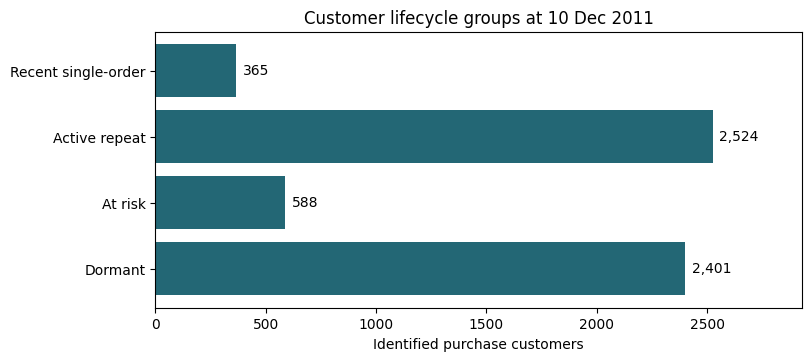

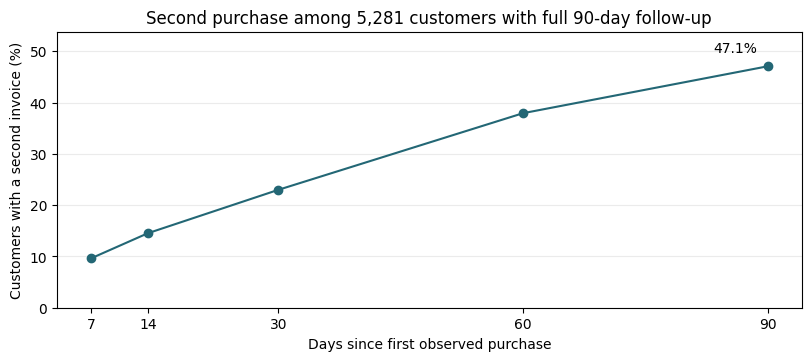

In [6]:
milestones = [7, 14, 30, 60, REPEAT_WINDOW_DAYS]
eligible_delays = eligible["SecondObservedPurchase"] - eligible["FirstObservedPurchase"]
repeat_summary = pd.DataFrame({"Day": milestones, "EligibleCustomers": len(eligible)})
repeat_summary["SecondOrderCustomers"] = [
    int(eligible_delays.le(pd.Timedelta(days=day)).sum()) for day in milestones
]
repeat_summary["RepeatRate"] = repeat_summary["SecondOrderCustomers"] / len(eligible)
assert repeat_summary["SecondOrderCustomers"].is_monotonic_increasing
assert repeat_summary["SecondOrderCustomers"].iloc[-1] == repeat_90

OUTPUT.mkdir(exist_ok=True)
customers.to_csv(OUTPUT / "customer_lifecycle.csv", index=False, float_format="%.3f")
lifecycle.to_csv(OUTPUT / "lifecycle_summary.csv", float_format="%.3f")
repeat_summary.to_csv(OUTPUT / "repeat_90_summary.csv", index=False, float_format="%.8f")

fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
bars = ax.barh(lifecycle.index, lifecycle["Customers"], color="#236775")
ax.bar_label(bars, labels=[f"{n:,}" for n in lifecycle["Customers"]], padding=5)
ax.set(xlabel="Identified purchase customers", title=f"Customer lifecycle groups at {snapshot_date:%d %b %Y}")
ax.invert_yaxis()
ax.margins(x=0.16)
fig.savefig(OUTPUT / "lifecycle_groups.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
percent = repeat_summary["RepeatRate"] * 100
ax.plot(repeat_summary["Day"], percent, marker="o", color="#236775")
ax.annotate(f"{percent.iloc[-1]:.1f}%", (milestones[-1], percent.iloc[-1]),
            xytext=(-8, 10), textcoords="offset points", ha="right")
ax.set(xlabel="Days since first observed purchase", ylabel="Customers with a second invoice (%)",
       title=f"Second purchase among {len(eligible):,} customers with full 90-day follow-up",
       xticks=milestones)
ax.margins(y=0.18)
ax.set_ylim(bottom=0)
ax.grid(axis="y", alpha=0.25)
fig.savefig(OUTPUT / "repeat_within_90_days.png", dpi=150)
plt.show()

## What the retailer could investigate next

Start with recent single-order customers when considering a second-order test. Use the repeat curve to frame timing hypotheses. For customers who have not purchased recently, compare group size and net recorded value before proposing a win-back test. Review flagged credits before considering outreach.

This is one historical retailer with wholesale customers. First observed purchase may be later than the real first purchase. Missing IDs narrow coverage, and recorded value includes invoice charges. Credits cannot be tied back to individual purchase invoices here. These limits matter when translating a historical pattern into a test.